In [1]:
import numpy as np
import pandas as pd

In [2]:
# ── 1단계: 데이터 불러오기 ──
freq = pd.read_csv("freMTPL2freq.csv")
print(f"계약 수: {len(freq):,}")
print(f"총 사고 건수: {freq.ClaimNb.sum():,}")
print(f"총 가입 기간(년): {freq.Exposure.sum():,.0f}")
print(f"단순 계산 1년당 사고율 = 총 사고 ÷ 총 기간 = "
      f"{freq.ClaimNb.sum() / freq.Exposure.sum():.4f}")

계약 수: 678,013
총 사고 건수: 36,102
총 가입 기간(년): 358,499
단순 계산 1년당 사고율 = 총 사고 ÷ 총 기간 = 0.1007


In [3]:
# ---------------------------------------------------------------- 1. 타깃 ClaimNb 점검
# 사고 5건 이상 9건 중 7건은 같은 차가 여러 계약 번호로 쪼개 기록된 것으로 보임
# 행을 지우면 "위험하다"는 정보까지 사라지므로, 삭제하지 않고 4로 cap
n_over = (freq.ClaimNb > 4).sum()
freq["ClaimNb"] = freq["ClaimNb"].clip(upper=4)
print(f"[1] ClaimNb 4에서 cap: {n_over}건 수정")

[1] ClaimNb 4에서 cap: 9건 수정


In [4]:
# ---------------------------------------------------------------- 2. Exposure 점검
# 1년 넘는 계약(대부분 1.01~1.04)은 기록 오차 → 1로 cap
# 분모가 커지면 1년당 사고율이 작게 계산됨 (예: 1 ÷ 2.01 = 0.50)
# 짧은 계약은 진짜 값이므로 그대로 둠 → offset이 알아서 보정
n_over = (freq.Exposure > 1).sum()
freq["Exposure"] = freq["Exposure"].clip(upper=1)
print(f"[2] Exposure 1에서 cap: {n_over:,}건 수정")

[2] Exposure 1에서 cap: 1,224건 수정


In [5]:
# ---------------------------------------------------------------- 3. 열 고르기
# ClaimNb = 타깃, Exposure = offset (심도와 반대로 버리지 않음!)
# Area는 Density를 6구간으로 자른 것 → 둘 다 넣으면 배수가 쪼개지고 SE가 커짐
freq = freq.drop(columns=["Area"])
print("[3] Area 제거, Exposure는 offset용으로 유지")

[3] Area 제거, Exposure는 offset용으로 유지


In [6]:
# ---------------------------------------------------------------- 4. 변수 변환 (전체 데이터에 바로 적용)
# 분할을 안 하므로 train에서 기준을 "배울" 필요 없이 전체 데이터로 바로 판단
# 희귀 범주는 행 수가 아니라 "사고 수"로 판단
# (사고 45건인 지역은 5건만 더 나도 사고율이 11% 흔들림)
def frequent_levels(d, col, min_claims=200):
    claims = d.groupby(col)["ClaimNb"].sum()
    return set(claims[claims >= min_claims].index)


keep_region = frequent_levels(freq, "Region")
keep_brand = frequent_levels(freq, "VehBrand")
print(f"[4] Other로 합칠 Region: {sorted(set(freq.Region) - keep_region)}")
print(f"    Other로 합칠 VehBrand: {sorted(set(freq.VehBrand) - keep_brand)}")

AGE_BINS = [17, 21, 25, 30, 40, 50, 60, 70, 80, 101]

freq["VehAge"] = freq["VehAge"].clip(upper=20)
freq["BonusMalus"] = freq["BonusMalus"].clip(upper=150)
freq["DrivAgeBin"] = pd.cut(freq["DrivAge"], bins=AGE_BINS).astype(str)
freq["VehPower"] = freq["VehPower"].clip(upper=12).astype(str)
freq["logDensity"] = np.log(freq["Density"])
freq["Region"] = freq["Region"].where(freq["Region"].isin(keep_region), "Other")
freq["VehBrand"] = freq["VehBrand"].where(freq["VehBrand"].isin(keep_brand), "Other")

[4] Other로 합칠 Region: ['Alsace', 'Auvergne', 'Champagne-Ardenne', 'Franche-Comte']
    Other로 합칠 VehBrand: ['B14']


In [7]:
# ---------------------------------------------------------------- 5. 최종 점검 + 저장
# 실수가 있어도 모델은 조용히 돌아가므로, 규칙이 지켜졌는지 assert로 바로 멈춰서 확인
cols = ["ClaimNb", "Exposure", "DrivAgeBin", "VehAge", "BonusMalus", "VehPower",
        "VehGas", "VehBrand", "Region", "logDensity"]
assert freq["IDpol"].is_unique, "IDpol 중복"
assert freq[cols].isna().sum().sum() == 0, "결측치 있음"
assert freq["ClaimNb"].max() <= 4, "ClaimNb cap 누락"
# Exposure = 0이면 offset log(0) = -inf → numpy는 경고만 내고 계속 계산함
assert freq["Exposure"].between(0, 1, inclusive="right").all(), "Exposure가 0 이하 또는 1 초과"
assert "nan" not in set(freq["DrivAgeBin"]), "나이 구간에 안 들어간 운전자 있음"
print(f"[5] 점검 통과 ✅  계약 {len(freq):,}건 · "
      f"1년당 사고율 {freq.ClaimNb.sum() / freq.Exposure.sum():.4f}")

keep = ["IDpol"] + cols
freq[keep].to_csv("freq_prep.csv", index=False)
print("\n저장: freq_prep.csv")

[5] 점검 통과 ✅  계약 678,013건 · 1년당 사고율 0.1006

저장: freq_prep.csv


## 전처리 전 vs 후 비교 시각화
위의 전처리 코드는 건드리지 않고, 원본 CSV를 다시 읽어서 `freq`(전처리 후)와 비교합니다.

[시각화] 사용 폰트: Malgun Gothic

[요약] 행은 하나도 지우지 않고, 값만 자르거나(cap) 묶음(Other·구간)
                 전처리 전   전처리 후
계약 수(행)         678013  678013
열 수                 12      11
ClaimNb 최댓값         16       4
Exposure 최댓값      2.01     1.0
VehAge 최댓값         100      20
BonusMalus 최댓값     230     150
VehPower 수준 수       12       9
Region 수준 수         21      18
VehBrand 수준 수       11      11
1년당 사고율         0.1007  0.1006


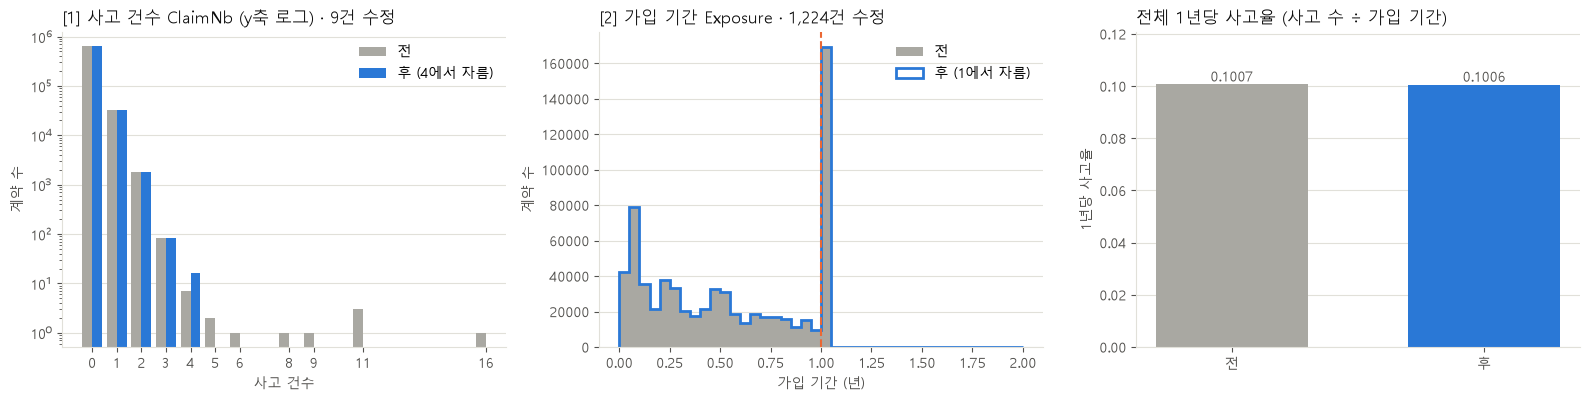

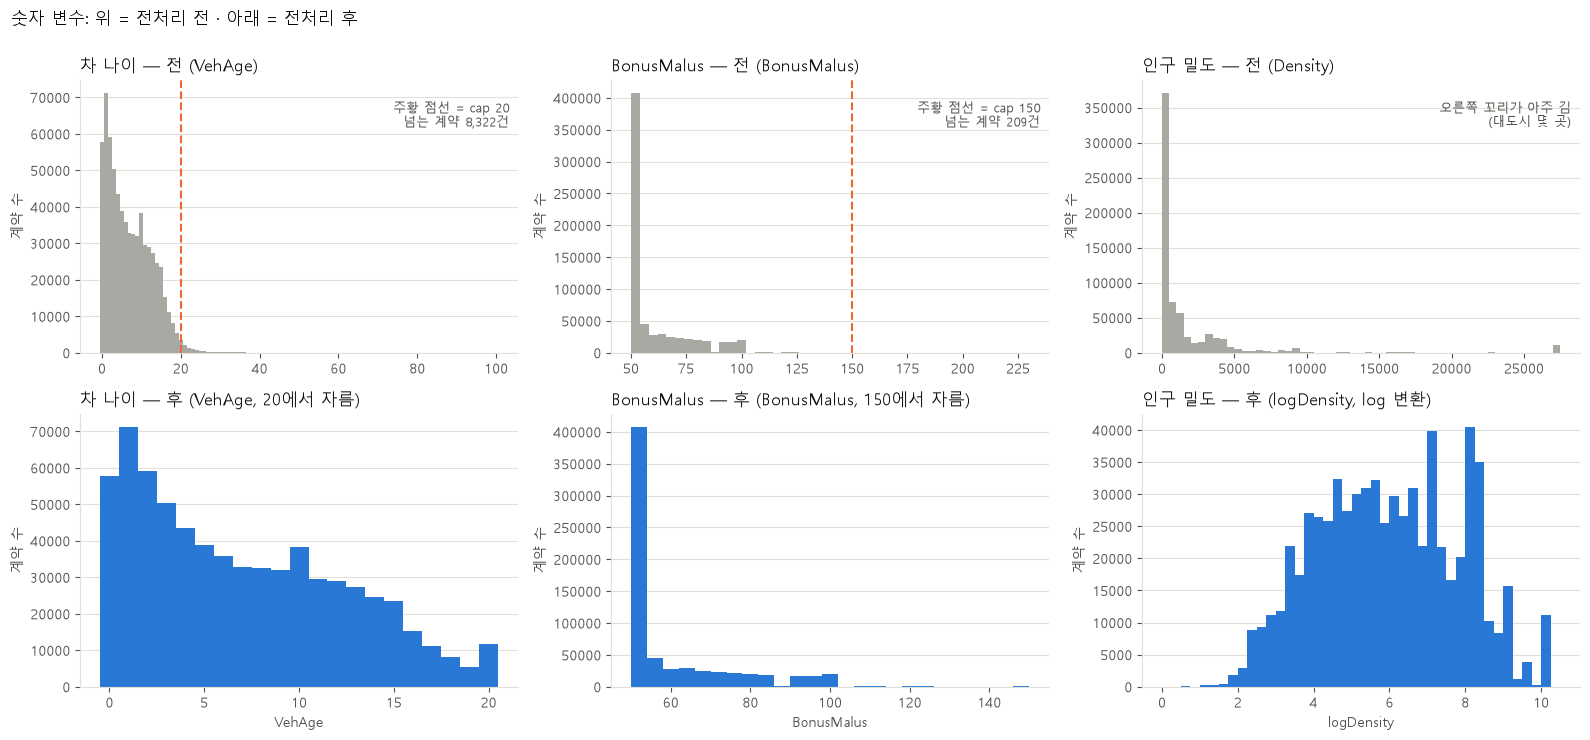

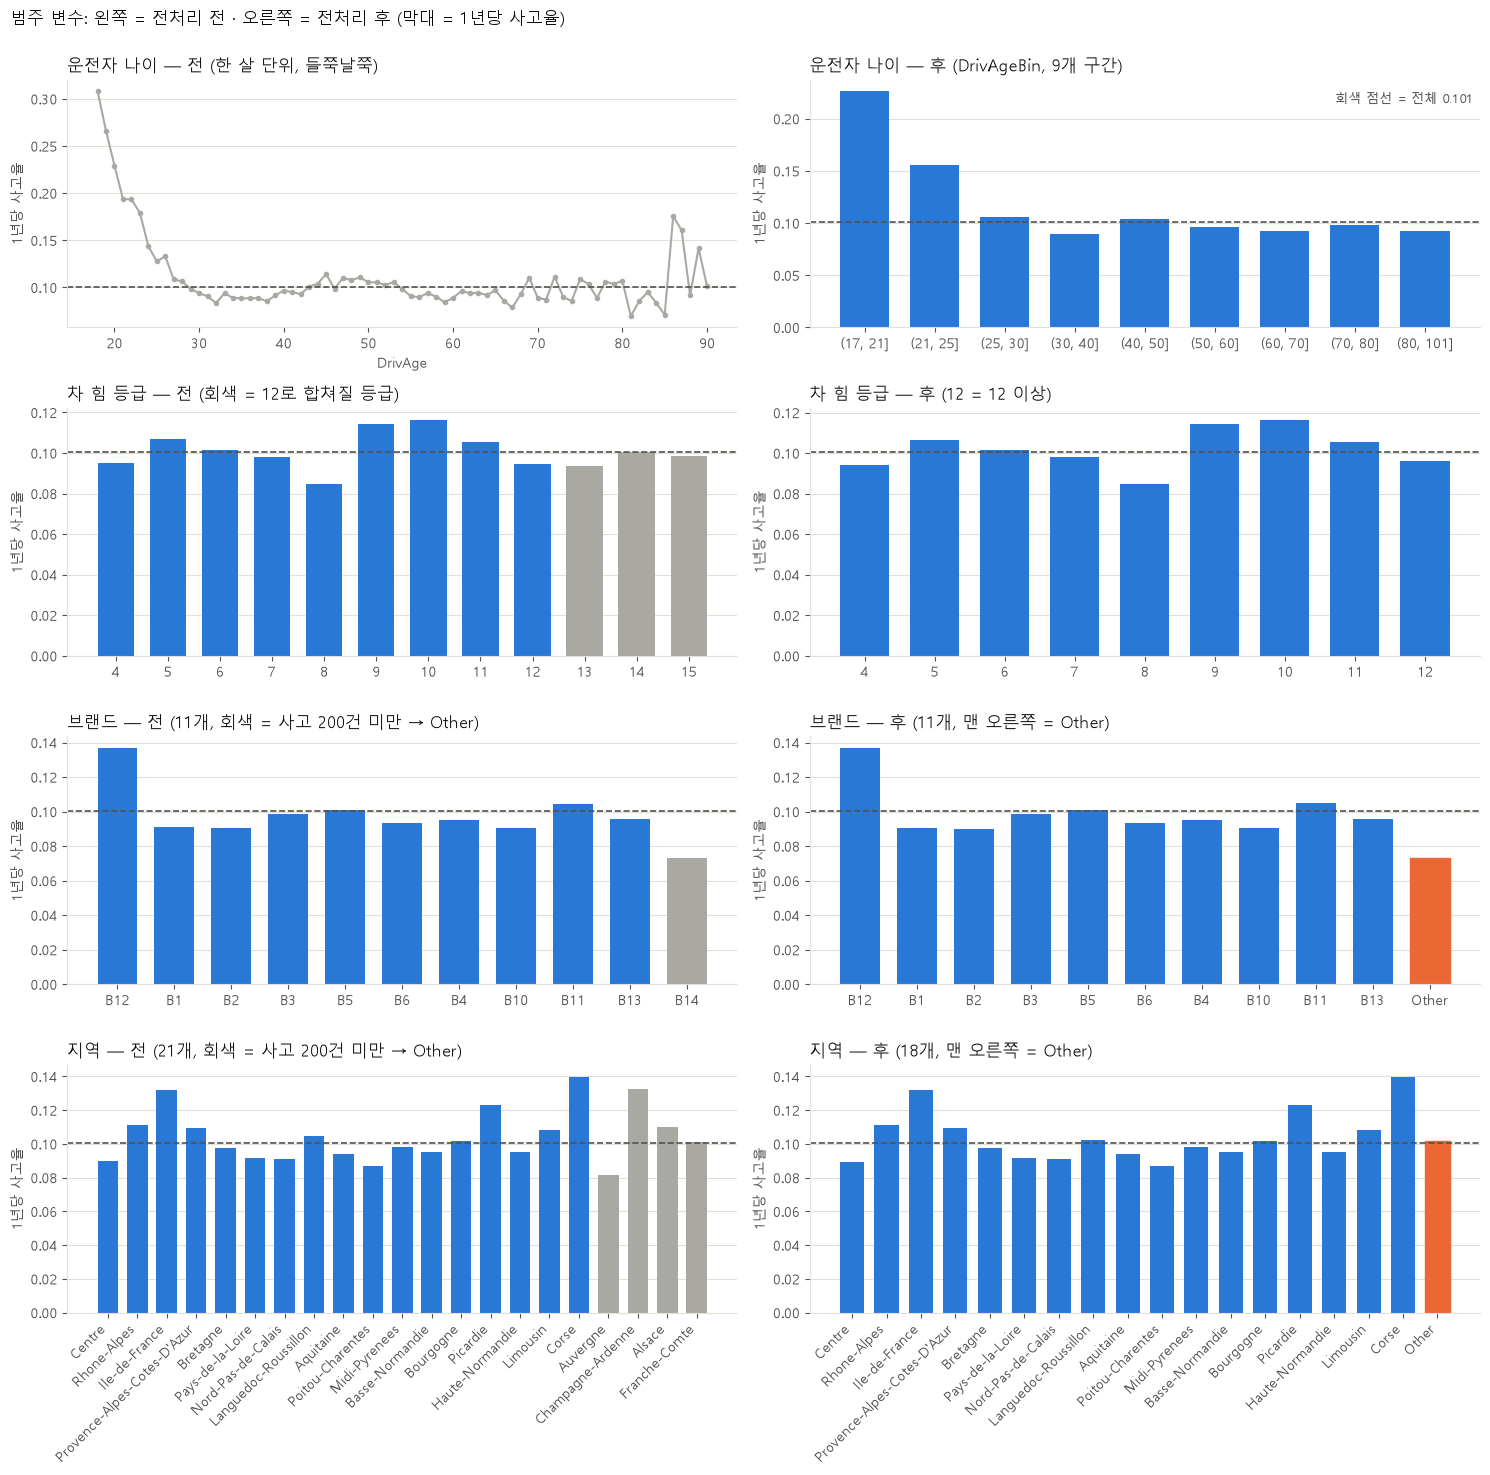

저장: freq_prep_viz_1_target.png, freq_prep_viz_2_numeric.png, freq_prep_viz_3_categorical.png


In [8]:
# ================================================================ 시각화: 전처리 전 vs 후
# 위의 전처리 코드는 건드리지 않고, 원본 CSV를 다시 읽어서(raw) 전처리 결과(freq)와 비교
# 그림 3장: 화면에 보여 주고 png로도 저장
# Mac · Windows · Colab 어디서 실행해도 한글이 나오도록 폰트를 자동으로 맞춤
import glob
import os
import subprocess
import sys

import matplotlib.pyplot as plt
from matplotlib import font_manager


# ---------------------------------------------------------------- 한글 폰트 자동 설정
def in_colab():
    # 노트북 셀에서 실행해도, !python 파일.py로 실행해도 Colab인지 알아냄
    return "google.colab" in sys.modules or "COLAB_RELEASE_TAG" in os.environ


def register_font_file():
    """폰트 '파일'을 찾아 matplotlib에 직접 등록
    (Colab은 폰트를 설치해도 matplotlib이 실행 중에는 새 폰트를 모름 → 직접 알려 주면 재시작 불필요)"""
    patterns = ["/usr/share/fonts/**/NanumGothic.ttf",            # Linux · Colab (fonts-nanum)
                "/usr/share/fonts/**/NotoSansCJK-Regular.ttc",    # Linux (fonts-noto-cjk)
                "C:/Windows/Fonts/malgun.ttf",                    # Windows
                "/System/Library/Fonts/AppleSDGothicNeo.ttc"]     # macOS
    for pattern in patterns:
        for path in glob.glob(pattern, recursive=True):
            font_manager.fontManager.addfont(path)
            return font_manager.FontProperties(fname=path).get_name()
    return None


def set_korean_font():
    # 1순위: matplotlib이 이미 알고 있는 한글 폰트
    installed = {f.name for f in font_manager.fontManager.ttflist}
    for name in ["Apple SD Gothic Neo", "AppleGothic", "Malgun Gothic",
                 "NanumGothic", "Noto Sans CJK KR", "Noto Sans KR"]:
        if name in installed:
            return name
    # 2순위: 컴퓨터에 파일은 있는데 matplotlib이 모르는 폰트
    name = register_font_file()
    if name:
        return name
    # 3순위: Colab이면 나눔 폰트를 설치한 뒤 다시 등록
    if in_colab():
        print("[시각화] Colab에 한글 폰트가 없어서 나눔 폰트를 설치하는 중... (10~30초)")
        subprocess.run("apt-get -qq install -y fonts-nanum > /dev/null 2>&1", shell=True)
        name = register_font_file()
        if name is None:   # 설치 목록이 오래돼서 실패한 경우 → 목록을 새로 받고 한 번 더
            subprocess.run("apt-get -qq update > /dev/null 2>&1 && "
                           "apt-get -qq install -y fonts-nanum > /dev/null 2>&1", shell=True)
            name = register_font_file()
        if name:
            return name
    print("⚠️ 한글 폰트를 찾지 못해서 그림의 한글이 □로 보일 수 있어요.")
    return None


font = set_korean_font()
if font:
    plt.rcParams["font.family"] = font
print(f"[시각화] 사용 폰트: {font}")

# ---------------------------------------------------------------- 공통 스타일 (전: 회색, 후: 파랑)
BLUE, ORANGE, GRAY = "#2a78d6", "#eb6834", "#a9a8a2"
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e1e0d9"
plt.rcParams.update({
    "axes.unicode_minus": False,   # 한글 폰트에서 마이너스(−)가 □로 깨지는 것 방지
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "grid.linewidth": 0.8,
    "xtick.color": INK2, "ytick.color": INK2, "axes.axisbelow": True,
    "figure.facecolor": "white", "axes.facecolor": "white",
})


def save_and_show(fig, filename):
    fig.tight_layout(rect=(0, 0, 1, 0.98))   # 맨 위 2%는 전체 제목 자리
    fig.savefig(filename, dpi=150)
    plt.show()   # Colab · Jupyter에서는 셀 아래에 그림이 바로 보임


def rate(d):
    """1년당 사고율 = 사고 수 ÷ 가입 기간 (빈도에서는 행 평균이 아니라 이걸 봐야 함)"""
    return d["ClaimNb"].sum() / d["Exposure"].sum()


def rate_by(d, col):
    g = d.groupby(col)[["ClaimNb", "Exposure"]].sum()
    return g["ClaimNb"] / g["Exposure"]


# 전처리 전 원본: 위에서 읽은 것과 같은 파일을 다시 읽음 (행 순서가 같아서 IDpol로 맞춰짐)
raw = pd.read_csv("freMTPL2freq.csv")
assert (raw["IDpol"].values == freq["IDpol"].values).all(), "원본과 전처리 결과의 행 순서가 다름"

# ---------------------------------------------------------------- 0. 요약표: 무엇이 바뀌었나
summary = pd.DataFrame({
    "전처리 전": [len(raw), raw.shape[1], raw.ClaimNb.max(), raw.Exposure.max(),
               raw.VehAge.max(), raw.BonusMalus.max(), raw.VehPower.nunique(),
               raw.Region.nunique(), raw.VehBrand.nunique(), f"{rate(raw):.4f}"],
    "전처리 후": [len(freq), len(keep), freq.ClaimNb.max(), freq.Exposure.max(),
               freq.VehAge.max(), freq.BonusMalus.max(), freq.VehPower.nunique(),
               freq.Region.nunique(), freq.VehBrand.nunique(), f"{rate(freq):.4f}"],
}, index=["계약 수(행)", "열 수", "ClaimNb 최댓값", "Exposure 최댓값", "VehAge 최댓값",
          "BonusMalus 최댓값", "VehPower 수준 수", "Region 수준 수", "VehBrand 수준 수",
          "1년당 사고율"])
print("\n[요약] 행은 하나도 지우지 않고, 값만 자르거나(cap) 묶음(Other·구간)")
display(summary) if "display" in globals() else print(summary)


# ---------------------------------------------------------------- 1. 타깃 ClaimNb와 Exposure
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))

# 왼쪽: ClaimNb 분포 — 0건이 너무 많아서 y축 로그
ax = axes[0]
before = raw["ClaimNb"].value_counts().sort_index()
after = freq["ClaimNb"].value_counts().sort_index()
ax.bar(before.index - 0.2, before.values, width=0.4, color=GRAY, label="전")
ax.bar(after.index + 0.2, after.values, width=0.4, color=BLUE, label="후 (4에서 자름)")
ax.set_yscale("log")
ax.set_xticks(before.index)
ax.set_title(f"[1] 사고 건수 ClaimNb (y축 로그) · {(raw.ClaimNb > 4).sum()}건 수정", loc="left")
ax.set_xlabel("사고 건수")
ax.set_ylabel("계약 수")
ax.legend(frameon=False)

# 가운데: Exposure 분포 — 1년 넘는 계약이 1로 모임
ax = axes[1]
b = np.arange(0, 2.05, 0.05)
ax.hist(raw["Exposure"], bins=b, color=GRAY, label="전")
ax.hist(freq["Exposure"], bins=b, histtype="step", linewidth=2, color=BLUE, label="후 (1에서 자름)")
ax.axvline(1, color=ORANGE, linewidth=1.5, linestyle="--")
ax.set_title(f"[2] 가입 기간 Exposure · {(raw.Exposure > 1).sum():,}건 수정", loc="left")
ax.set_xlabel("가입 기간 (년)")
ax.set_ylabel("계약 수")
ax.legend(frameon=False)

# 오른쪽: 전체 1년당 사고율 전 vs 후 — 사고 46건, 가입 기간 139년이 줄어 거의 그대로
ax = axes[2]
vals = [rate(raw), rate(freq)]
ax.bar([0, 1], vals, color=[GRAY, BLUE], width=0.6)
for i, v in enumerate(vals):
    ax.text(i, v, f"{v:.4f}", ha="center", va="bottom", color=INK2)
ax.set_xticks([0, 1], ["전", "후"])
ax.set_ylim(0, max(vals) * 1.2)
ax.set_title("전체 1년당 사고율 (사고 수 ÷ 가입 기간)", loc="left")
ax.set_ylabel("1년당 사고율")

save_and_show(fig, "freq_prep_viz_1_target.png")


# ---------------------------------------------------------------- 2. 숫자 변수: 분포 전 vs 후
# 위 = 전처리 전 원본, 아래 = 전처리 후 (cap 위치에 막대가 솟음 = 잘린 값들이 모인 것)
num_cols = [("VehAge", "VehAge", "차 나이", "20에서 자름",
             np.arange(-0.5, 101.5, 1), np.arange(-0.5, 21.5, 1)),
            ("BonusMalus", "BonusMalus", "BonusMalus", "150에서 자름",
             np.arange(50, 232, 4), np.arange(50, 154, 4)),
            ("Density", "logDensity", "인구 밀도", "log 변환",
             np.linspace(0, 27500, 56), np.linspace(0, 10.5, 43))]

fig, axes = plt.subplots(2, 3, figsize=(16, 7.5))
for top, bottom, (c0, c1, name, how, b0, b1) in zip(axes[0], axes[1], num_cols):
    top.hist(raw[c0], bins=b0, color=GRAY)
    top.set_title(f"{name} — 전 ({c0})", loc="left")
    top.set_ylabel("계약 수")

    bottom.hist(freq[c1], bins=b1, color=BLUE)
    bottom.set_title(f"{name} — 후 ({c1}, {how})", loc="left")
    bottom.set_ylabel("계약 수")
    bottom.set_xlabel(c1)

    # 자른 경우: 몇 건이 잘렸는지 표시
    if c0 == c1:
        cap = freq[c1].max()
        n = (raw[c0] > cap).sum()
        top.axvline(cap, color=ORANGE, linewidth=1.5, linestyle="--")
        top.text(0.98, 0.92, f"주황 점선 = cap {cap}\n넘는 계약 {n:,}건", transform=top.transAxes,
                 ha="right", va="top", fontsize=9, color=INK2)
top_d = axes[0][2]
top_d.text(0.98, 0.92, "오른쪽 꼬리가 아주 김\n(대도시 몇 곳)", transform=top_d.transAxes,
           ha="right", va="top", fontsize=9, color=INK2)
fig.suptitle("숫자 변수: 위 = 전처리 전 · 아래 = 전처리 후", x=0.01, ha="left", color=INK)
save_and_show(fig, "freq_prep_viz_2_numeric.png")


# ---------------------------------------------------------------- 3. 범주 변수: 1년당 사고율 전 vs 후
# 막대 = 수준별 1년당 사고율, 점선 = 전체 평균
# 전: 회색 막대 = Other로 합쳐질 수준 / 후: 주황 막대 = 합쳐진 Other
overall = rate(freq)


def draw_rate(ax, d, col, order, highlight, title, rot=0):
    r = rate_by(d, col).reindex(order)
    x = np.arange(len(order))
    colors = [GRAY if lv in highlight else BLUE for lv in order]
    ax.bar(x, r.values, color=colors, width=0.7)
    ax.axhline(overall, color=INK2, linewidth=1.2, linestyle="--")
    ax.set_xticks(x, order, rotation=rot, ha="right" if rot else "center")
    ax.set_title(title, loc="left")
    ax.set_ylabel("1년당 사고율")


fig, axes = plt.subplots(4, 2, figsize=(15, 15))

# (1) 운전자 나이: 전 = 한 살 단위(들쭉날쭉) → 후 = 9개 구간
ax = axes[0][0]
r = rate_by(raw, "DrivAge")
ex = raw.groupby("DrivAge")["Exposure"].sum()
r = r[ex >= 100]   # 가입 기간이 너무 적은 나이는 흔들려서 제외
ax.plot(r.index, r.values, color=GRAY, marker="o", markersize=3)
ax.axhline(overall, color=INK2, linewidth=1.2, linestyle="--")
ax.set_title("운전자 나이 — 전 (한 살 단위, 들쭉날쭉)", loc="left")
ax.set_xlabel("DrivAge")
ax.set_ylabel("1년당 사고율")
age_order = sorted(freq["DrivAgeBin"].unique(), key=lambda s: float(s.strip("(]").split(",")[0]))
draw_rate(axes[0][1], freq, "DrivAgeBin", age_order, set(), "운전자 나이 — 후 (DrivAgeBin, 9개 구간)")

# (2) 차 힘 등급: 전 = 4~15 → 후 = 4~12 (12 이상은 12)
power_before = sorted(raw["VehPower"].unique())
draw_rate(axes[1][0], raw, "VehPower", power_before, {p for p in power_before if p > 12},
          "차 힘 등급 — 전 (회색 = 12로 합쳐질 등급)")
draw_rate(axes[1][1], freq, "VehPower", [str(p) for p in range(4, 13)], set(),
          "차 힘 등급 — 후 (12 = 12 이상)")

# (3) 브랜드, (4) 지역: 전 = 원래 수준 → 후 = 희귀 수준을 Other로
for row, col, name in [(axes[2], "VehBrand", "브랜드"), (axes[3], "Region", "지역")]:
    claims = raw.groupby(col)["ClaimNb"].sum().sort_values(ascending=False)
    merged = set(raw[col]) - set(freq[col])          # Other로 간 수준
    rot = 45 if col == "Region" else 0
    draw_rate(row[0], raw, col, claims.index.tolist(), merged,
              f"{name} — 전 ({raw[col].nunique()}개, 회색 = 사고 200건 미만 → Other)", rot)
    order_after = [lv for lv in claims.index if lv not in merged] + ["Other"]
    draw_rate(row[1], freq, col, order_after, set(),
              f"{name} — 후 ({freq[col].nunique()}개, 맨 오른쪽 = Other)", rot)
    row[1].patches[-1].set_color(ORANGE)              # Other 막대만 주황

axes[0][1].text(0.99, 0.95, f"회색 점선 = 전체 {overall:.3f}", transform=axes[0][1].transAxes,
                ha="right", va="top", fontsize=9, color=INK2)
fig.suptitle("범주 변수: 왼쪽 = 전처리 전 · 오른쪽 = 전처리 후 (막대 = 1년당 사고율)",
             x=0.01, ha="left", color=INK)
save_and_show(fig, "freq_prep_viz_3_categorical.png")

print("저장: freq_prep_viz_1_target.png, freq_prep_viz_2_numeric.png, freq_prep_viz_3_categorical.png")